In [1]:
from collections.abc import Mapping
from datetime import datetime
from functools import partial
from pathlib import Path

import torch
from matplotlib.figure import Figure
from torch.utils.data import DataLoader
from torch.utils.tensorboard import SummaryWriter
from torchvision.datasets import ImageFolder
from torchvision.transforms import v2

from mlkit.core.callbacks import Callback, ProgressLogger
from mlkit.core.trainer import Trainer
from mlkit.data.splitter import StratifiedSplitter
from mlkit.data.subsets import TransformSubset
from mlkit.metrics.collections import multiclass_metrics
from mlkit.models.cnn_classifier import CNNClassifier, CNNConfig, ConvBlockConfig
from mlkit.tasks.classification import ClassificationTask
from mlkit.utils.logs import setup_logging
from mlkit.visual.confusion import confusion_matrix, plot_confusion_matrix
from mlkit.visual.curves import plot_history
from mlkit.visual.images import plot_image_grid
from mlkit.visual.saver import FigureSaver
from mlkit.visual.style import use_style

setup_logging()
use_style()

DATASET_PATH = Path("../../datasets/raw/mnist_png")
TRAINING_PATH = DATASET_PATH / "training"
TESTING_PATH = DATASET_PATH / "testing"

SEED = 42
BATCH_SIZE = 100
EPOCHS = 20
LEARNING_RATE = 1e-3
VAL_FRACTION = 0.2
NUM_WORKERS = 2

In [2]:
transform = v2.Compose([
    v2.Grayscale(),
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
])

training_dataset = ImageFolder(TRAINING_PATH)
testing_dataset = ImageFolder(TESTING_PATH, transform=transform)

In [3]:
splitter = StratifiedSplitter((1 - VAL_FRACTION, VAL_FRACTION), seed=SEED)
train_idx, val_idx = splitter.split(training_dataset.targets)
train_ds = TransformSubset(training_dataset, train_idx, transform)
val_ds = TransformSubset(training_dataset, val_idx, transform)

train_loader = DataLoader(
    train_ds, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=NUM_WORKERS, pin_memory=True, persistent_workers=True,
)
val_loader = DataLoader(
    val_ds, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=True, persistent_workers=True,
)
test_loader = DataLoader(testing_dataset, batch_size=BATCH_SIZE, shuffle=False,)

In [4]:
sample, _ = train_ds[0]
channels, height, width = sample.size()

cnn_config = CNNConfig(
    in_channels=channels,
    input_size=(height, width),
    num_classes=len(training_dataset.classes),
    conv_blocks=(
        ConvBlockConfig(out_channels=24, kernel_size=3, padding=0, pool_size=2),
        ConvBlockConfig(out_channels=36, kernel_size=3, padding=0, pool_size=2),
    ),
    hidden_sizes=(128,),
)

In [ ]:
torch.manual_seed(SEED)

task = ClassificationTask(
    model=CNNClassifier(config=cnn_config),
    optimizer=partial(torch.optim.Adam, lr=LEARNING_RATE),
    metrics=multiclass_metrics(num_classes=cnn_config.num_classes),
)

run_name = f"lab1_part1_{datetime.now():%Y%m%d_%H%M%S}"
writer = SummaryWriter(log_dir=f"runs/{run_name}")
saver = FigureSaver(Path("artifacts") / run_name)


def save_figure(fig: Figure, name: str) -> None:
    saver.save(fig, name)
    writer.add_figure(name, fig, close=False)


class TensorBoardScalars(Callback):
    def __init__(self, writer: SummaryWriter) -> None:
        self.writer = writer

    def on_epoch_end(self, trainer: Trainer, epoch: int, logs: Mapping[str, float]) -> None:
        for key, value in logs.items():
            split, _, name = key.partition("/")
            self.writer.add_scalars(name, {split: value}, epoch)


hparams: dict[str, int | float | str] = {
    "batch_size": BATCH_SIZE,
    "epochs": EPOCHS,
    "optimizer": type(task.opt).__name__,
    "learning_rate": LEARNING_RATE,
}
writer.add_text("hparams", "\n".join(f"- {name}: {value}" for name, value in hparams.items()))

trainer = Trainer(callbacks=[ProgressLogger(), TensorBoardScalars(writer)])
history = trainer.fit(task, train_loader, val_loader, epochs=EPOCHS)

Epoch 1 | train/loss 0.3189 train/accuracy 0.9049 train/f1 0.9043 train/precision 0.905 train/recall 0.904 val/loss 0.1118 val/accuracy 0.9654 val/f1 0.9654 val/precision 0.966 val/recall 0.9654 | 28.1s
Epoch 2 | train/loss 0.08052 train/accuracy 0.9749 train/f1 0.9748 train/precision 0.9748 train/recall 0.9747 val/loss 0.06704 val/accuracy 0.9797 val/f1 0.9795 val/precision 0.9798 val/recall 0.9794 | 12.1s
Epoch 3 | train/loss 0.05618 train/accuracy 0.9825 train/f1 0.9824 train/precision 0.9824 train/recall 0.9823 val/loss 0.05374 val/accuracy 0.9823 val/f1 0.9821 val/precision 0.9822 val/recall 0.9821 | 11.9s
Epoch 4 | train/loss 0.0435 train/accuracy 0.9861 train/f1 0.986 train/precision 0.986 train/recall 0.986 val/loss 0.05341 val/accuracy 0.9826 val/f1 0.9824 val/precision 0.9828 val/recall 0.9821 | 12.3s
Epoch 5 | train/loss 0.03572 train/accuracy 0.9893 train/f1 0.9893 train/precision 0.9893 train/recall 0.9892 val/loss 0.04638 val/accuracy 0.9849 val/f1 0.9848 val/precision 0.

Best val loss 0.0383 at epoch 11
Best val accuracy 0.9897 at epoch 15


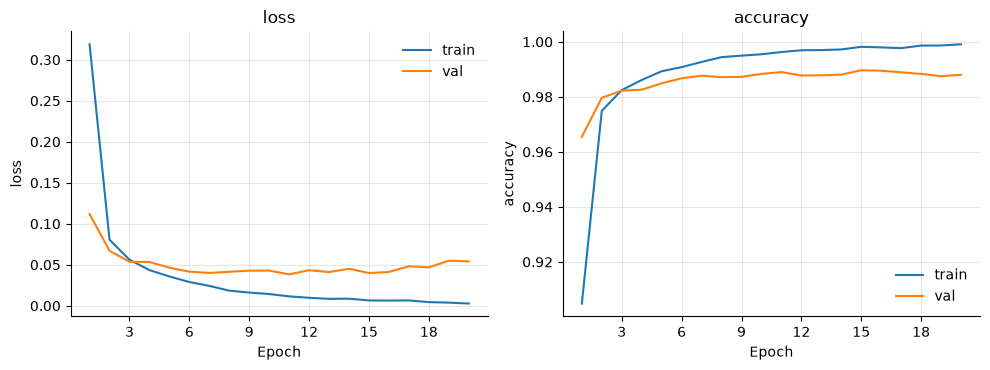

In [6]:
save_figure(plot_history(history, ["loss", "accuracy"]), "training_curves")

best_epoch, best_loss = history.best("val/loss", mode="min")
best_acc_epoch, best_acc = history.best("val/accuracy", mode="max")
print(f"Best val loss {best_loss:.4f} at epoch {best_epoch}")
print(f"Best val accuracy {best_acc:.4f} at epoch {best_acc_epoch}")

In [7]:
test_results = trainer.evaluate(task, test_loader)
probs, targets = task.predict(test_loader)
preds = probs.argmax(dim=1)
print(test_results)

{'loss': 0.052451159378144326, 'accuracy': 0.9897000193595886, 'f1': 0.9895865321159363, 'precision': 0.9897433519363403, 'recall': 0.9894916415214539}


WindowsPath('artifacts/lab1_part1_20261017_190303/misclassified.png')

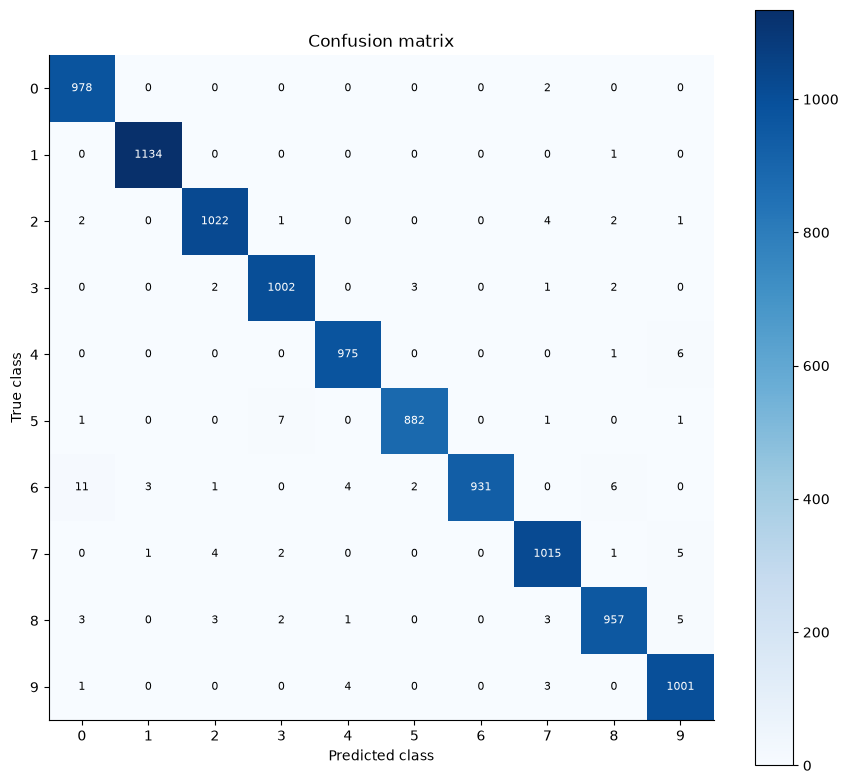

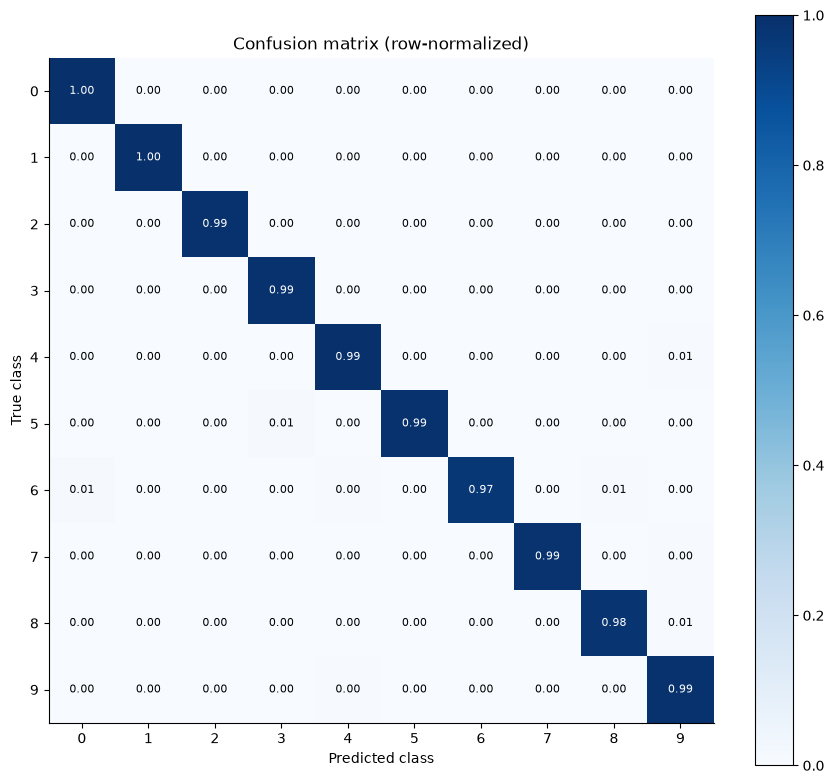

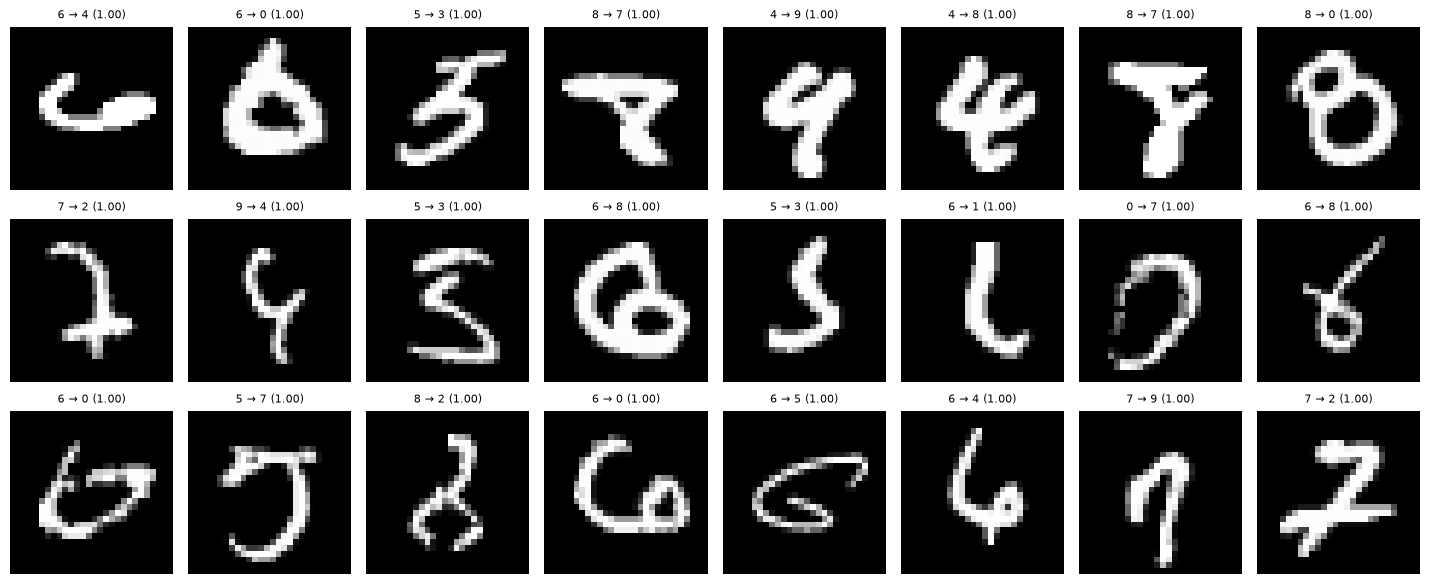

In [8]:
class_names: list[str] = testing_dataset.classes
matrix = confusion_matrix(preds, targets, num_classes=len(class_names))

save_figure(plot_confusion_matrix(matrix, class_names), "confusion_counts")
save_figure(plot_confusion_matrix(matrix, class_names, normalize=True), "confusion_normalized")

wrong = (preds != targets).nonzero().flatten()
confidence = probs[wrong, preds[wrong]]
errors = wrong[confidence.argsort(descending=True)][:24].tolist()
error_images = torch.stack([testing_dataset[i][0] for i in errors])
error_titles = [
    f"{class_names[targets[i]]} → {class_names[preds[i]]} ({probs[i, preds[i]]:.2f})"
    for i in errors
]
save_figure(plot_image_grid(error_images, error_titles), "misclassified")

In [9]:
writer.add_hparams(
    hparams,
    {f"test/{name}": value for name, value in test_results.items()},
    run_name="hparams",
)
writer.close()

In [11]:
import os
import shutil
import subprocess
import sys
import tempfile

os.environ["TENSORBOARD_BINARY"] = str(Path(sys.executable).parent / "tensorboard.exe")
subprocess.run(["taskkill", "/IM", "tensorboard.exe", "/T", "/F"], capture_output=True)
shutil.rmtree(Path(tempfile.gettempdir()) / ".tensorboard-info", ignore_errors=True)

%reload_ext tensorboard
%tensorboard --logdir runs